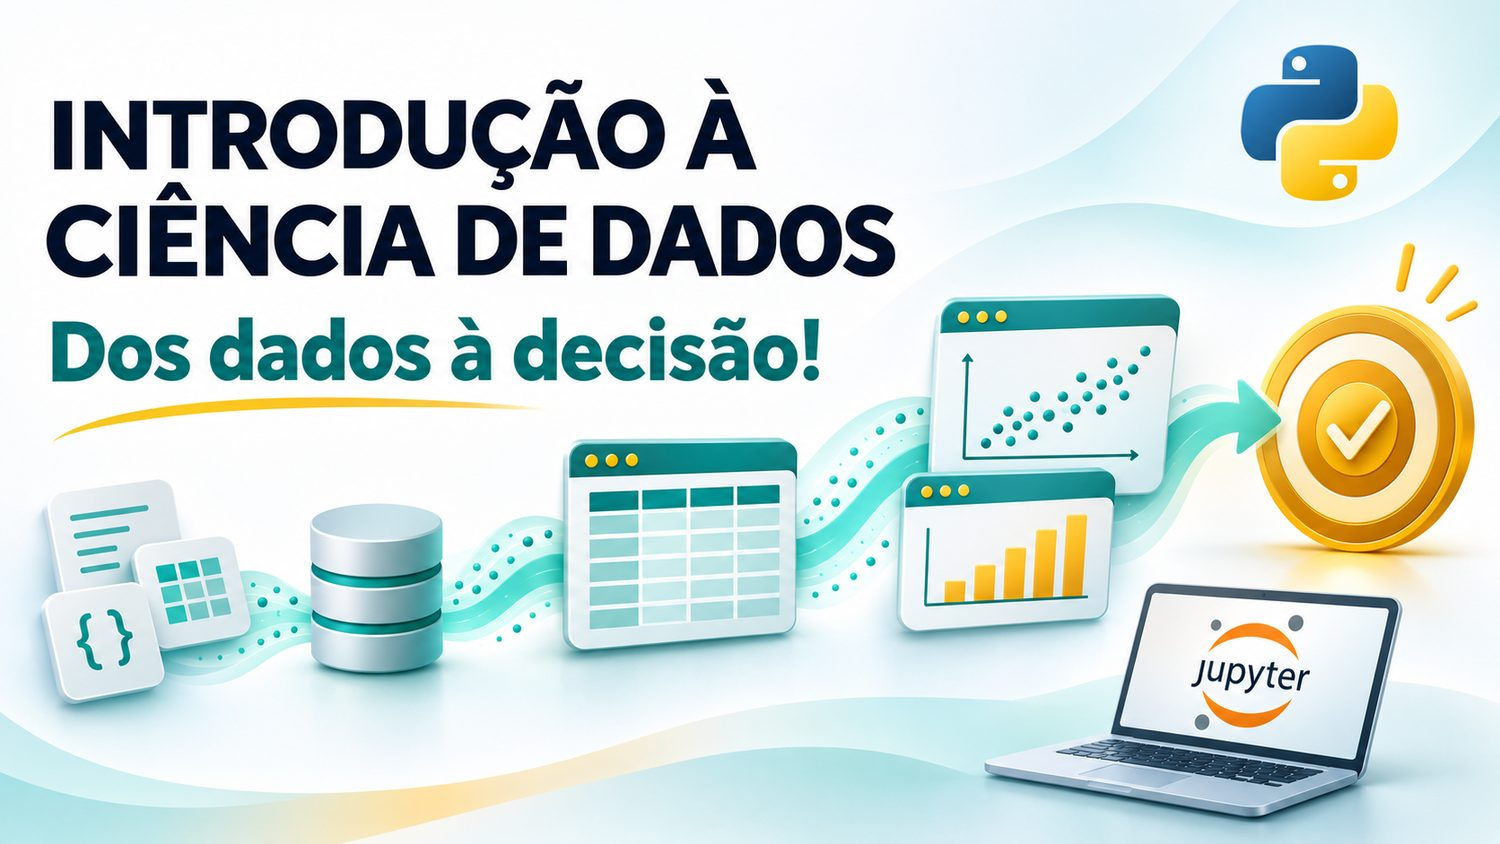

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_6_modelos_supervisionados/07_Projeto_Modelo_Supervisionado.ipynb)

# Capítulo 7 – Projeto: um modelo supervisionado de ponta a ponta

Neste projeto recebes dados que nunca viste e constróis um modelo de classificação do princípio ao fim: do enquadramento à avaliação final, passando pela escolha entre modelos e pelo diagnóstico. O roteiro tem oito passos; cada um tem perguntas, uma célula para o teu código e uma solução possível.

> **Objetivos:** aplicar os capítulos 1 a 6 a dados novos; escolher a métrica a partir da decisão; detetar uma fuga de informação; comparar um KNN e uma árvore com validação cruzada; diagnosticar sobreajuste; escolher um limiar pelo custo; avaliar uma única vez no teste; explicar o modelo e os seus limites.

**Pré-requisitos:** capítulos 1 a 6 deste módulo, e o módulo 4.

**Duração sugerida:** 2 horas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

## O problema

Um ginásio com cerca de 5 000 sócios perde todos os trimestres uma parte deles. A direção quer **telefonar aos sócios em risco de cancelar**, para lhes oferecer um mês grátis ou um plano de treino novo. Não há equipa para telefonar a todos.

- Cada telefonema custa cerca de **4 €** (tempo do funcionário e oferta).
- Cada sócio que cancela sem ter sido contactado representa uma perda de cerca de **60 €**.

Tens uma fotografia dos sócios no início de um trimestre e a informação de quem cancelou durante esse trimestre. A função seguinte gera os dados (sintéticos). Não a leias com atenção: num projeto real não saberias como foram produzidos.

In [2]:
def gerar_socios(n=5000, semente=71):
    """Gera os sócios de um ginásio fictício no início de um trimestre (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    meses = rng.gamma(1.6, 11, n).round().clip(1, 120).astype(int)
    idade = rng.normal(37, 12, n).round().clip(16, 80).astype(int)
    plano = rng.choice(["mensal", "trimestral", "anual"], n, p=[0.5, 0.2, 0.3])
    aulas = rng.random(n) < 0.35
    distancia = rng.gamma(2.0, 1.8, n).clip(0.2, 20).round(1)
    visitas = rng.poisson(np.clip(7.5 + 3.0 * aulas - 0.35 * distancia + rng.normal(0, 3, n), 0.3, None))
    dias_sem_vir = np.where(visitas == 0, rng.integers(30, 90, n), rng.geometric(np.clip(visitas / 30, 0.03, 0.9), n)).clip(0, 90)
    mensalidade = (np.select([plano == "mensal", plano == "trimestral"], [42.0, 38.0], 32.0) + 8.0 * aulas + rng.normal(0, 2, n)).round(2)
    cacifo = rng.integers(1, 400, n)
    risco = (-2.7 + 1.9 * (visitas <= 2) + 1.5 * (dias_sem_vir > 21) + 1.6 * (visitas <= 2) * (dias_sem_vir > 21)
             - 1.5 * (plano == "anual") - 0.5 * (plano == "trimestral") + 0.9 * (meses <= 3) - 0.7 * aulas + 0.05 * distancia)
    cancelou = rng.random(n) < 1 / (1 + np.exp(-risco))
    devolucao = np.where(cancelou & (plano != "mensal"), (mensalidade * rng.uniform(0.3, 1.5, n)).round(2), 0.0)
    tabela = pd.DataFrame({"socio_id": np.arange(1, n + 1), "meses_de_socio": meses, "idade": idade, "plano": plano, "aulas_de_grupo": aulas,
                           "distancia_km": distancia, "visitas_ultimo_mes": visitas, "dias_desde_ultima_visita": dias_sem_vir,
                           "mensalidade": mensalidade, "numero_cacifo": cacifo, "valor_devolvido": devolucao, "cancelou": cancelou})
    tabela.loc[rng.random(n) < 0.04, "idade"] = np.nan
    return tabela


socios = gerar_socios()
socios.head()

,socio_id,meses_de_socio,idade,plano,aulas_de_grupo,distancia_km,visitas_ultimo_mes,dias_desde_ultima_visita,mensalidade,numero_cacifo,valor_devolvido,cancelou
0,1,15,21.0,anual,False,4.4,1,15,30.20,157,0.0,False
1,2,13,40.0,mensal,True,3.3,13,2,50.54,70,0.0,False
2,3,21,17.0,mensal,True,12.1,4,5,45.03,361,0.0,False
3,4,19,51.0,trimestral,True,4.8,7,8,47.55,312,0.0,False
4,5,8,47.0,mensal,False,0.5,11,3,40.94,295,0.0,False


| Coluna | Significado |
| --- | --- |
| `socio_id` | Identificador do sócio |
| `meses_de_socio` | Há quantos meses é sócio |
| `idade` | Idade, em anos |
| `plano` | Mensal, trimestral ou anual |
| `aulas_de_grupo` | Se está inscrito em aulas de grupo |
| `distancia_km` | Distância de casa ao ginásio |
| `visitas_ultimo_mes` | Número de visitas no último mês |
| `dias_desde_ultima_visita` | Dias desde a última visita |
| `mensalidade` | Valor pago por mês, em euros |
| `numero_cacifo` | Número do cacifo atribuído |
| `valor_devolvido` | Valor devolvido ao sócio durante o trimestre, em euros |
| `cancelou` | Se cancelou durante o trimestre (o alvo) |

## Passo 1 – Enquadrar

- Qual é o alvo, e qual é a classe positiva? Com que frequência ocorre?
- Que erros pode o modelo cometer, e quanto custa cada um?
- Que métrica faz sentido? E qual é a linha de base?

In [3]:
# Passo 1

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
print(socios.shape)
print(f"Taxa de cancelamento: {socios['cancelou'].mean():.1%}")
print(socios.isna().sum()[socios.isna().sum() > 0])
print("Custo de não telefonar a ninguém:", int(socios["cancelou"].sum() * 60), "€ | de telefonar a todos:", len(socios) * 4, "€")
```

O alvo é `cancelou`, e a classe positiva é «cancelou» (cerca de um sócio em cada nove). Um **falso positivo** é um telefonema desnecessário (4 €); um **falso negativo** é um sócio perdido sem tentativa de o reter (60 €). O segundo erro custa quinze vezes mais: a **sensibilidade** importa mais do que a precisão, e a exatidão seria enganadora com esta proporção de classes.

Usamos a **AUC** para comparar modelos (mede a capacidade de ordenar os sócios por risco, sem depender do limiar) e o **custo total** para escolher o limiar. As linhas de base são duas: não telefonar a ninguém e telefonar a todos. Um modelo só é útil se custar menos do que a mais barata das duas.

Há valores em falta na idade (cerca de 4%), que o pipeline terá de tratar.

</details>

## Passo 2 – Separar o teste e procurar fugas

- Separa 20% dos sócios para o teste, de forma estratificada. Não lhes toques até ao passo 7.
- Antes de treinar: há alguma coluna que **não estaria disponível** no momento da previsão (o início do trimestre)? Há alguma que não deva entrar por outro motivo?

Sugestão: compara a média de cada coluna numérica entre os sócios que cancelaram e os que não cancelaram.

In [4]:
# Passo 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from sklearn.model_selection import train_test_split

desenvolvimento, teste = train_test_split(socios, test_size=0.2, random_state=0, stratify=socios["cancelou"])
print(desenvolvimento.groupby("cancelou").mean(numeric_only=True).T.round(2))
print((desenvolvimento["valor_devolvido"] > 0).groupby(desenvolvimento["cancelou"]).mean())
```

A coluna `valor_devolvido` é **zero para todos os sócios que não cancelaram** e positiva para muitos dos que cancelaram. É uma devolução feita *durante* o trimestre, por causa do cancelamento: uma consequência do alvo, que não existe no momento da previsão. É uma **fuga de informação** e tem de sair. Um modelo treinado com ela teria resultados excelentes e seria inútil.

Saem também `socio_id` (um identificador não é um atributo) e, por conhecimento do problema, `numero_cacifo` (um número atribuído ao acaso). Este último podia ficar e deixar a decisão à validação; retirá-lo já protege o KNN.

</details>

In [5]:
# A partir daqui usamos esta divisão e estes atributos (ver a solução do passo 2)
from sklearn.model_selection import train_test_split

desenvolvimento, teste = train_test_split(socios, test_size=0.2, random_state=0, stratify=socios["cancelou"])
numericas = ["meses_de_socio", "idade", "aulas_de_grupo", "distancia_km", "visitas_ultimo_mes", "dias_desde_ultima_visita", "mensalidade"]
nominais = ["plano"]
atributos = numericas + nominais
X, y = desenvolvimento[atributos], desenvolvimento["cancelou"]
print(f"Desenvolvimento: {len(X)} sócios | Teste: {len(teste)} sócios | {len(atributos)} atributos")

Desenvolvimento: 4000 sócios | Teste: 1000 sócios | 8 atributos


## Passo 3 – Um pipeline e um primeiro modelo

- Constrói a preparação: imputação da idade pela mediana, normalização das colunas numéricas e codificação do plano.
- Avalia uma regressão logística por validação cruzada estratificada de 5 partes, com a AUC.
- Para veres o efeito da fuga, repete acrescentando `valor_devolvido` aos atributos.

In [6]:
# Passo 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

partes = StratifiedKFold(5, shuffle=True, random_state=0)


def preparar(colunas_numericas=numericas, colunas_nominais=nominais):
    passos = [("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), colunas_numericas)]
    if colunas_nominais:
        passos.append(("cat", OneHotEncoder(handle_unknown="ignore"), colunas_nominais))
    return ColumnTransformer(passos)


logistica = make_pipeline(preparar(), LogisticRegression(max_iter=2000))
auc = cross_val_score(logistica, X, y, cv=partes, scoring="roc_auc")
print(f"Regressão logística: AUC {auc.mean():.3f} ± {auc.std():.3f}")

com_fuga = make_pipeline(preparar(numericas + ["valor_devolvido"]), LogisticRegression(max_iter=2000))
auc_fuga = cross_val_score(com_fuga, desenvolvimento[atributos + ["valor_devolvido"]], y, cv=partes, scoring="roc_auc")
print(f"Com a coluna valor_devolvido: AUC {auc_fuga.mean():.3f}")
```

A regressão logística dá uma AUC razoável, e é a referência a bater. Com a coluna da devolução, a AUC sobe bastante, sem que o modelo tenha aprendido nada de útil: está a ler o resultado numa coluna que só existe depois dele. A validação cruzada **não deteta** este tipo de fuga, porque a coluna está presente em todas as partes. Só o conhecimento do problema a apanha.

</details>

In [7]:
# A partir daqui usamos estas definições (ver a solução do passo 3)
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

partes = StratifiedKFold(5, shuffle=True, random_state=0)


def preparar(colunas_numericas=numericas, colunas_nominais=nominais):
    passos = [("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), colunas_numericas)]
    if colunas_nominais:
        passos.append(("cat", OneHotEncoder(handle_unknown="ignore"), colunas_nominais))
    return ColumnTransformer(passos)


logistica = make_pipeline(preparar(), LogisticRegression(max_iter=2000))

## Passo 4 – Um KNN

- Procura o melhor k com `GridSearchCV`, usando todos os atributos.
- Repete com um conjunto mais pequeno de atributos, escolhidos por ti. Melhora?

In [8]:
# Passo 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

valores_k = {"kneighborsclassifier__n_neighbors": [5, 15, 31, 61, 101, 151]}
knn_todos = GridSearchCV(make_pipeline(preparar(), KNeighborsClassifier()), valores_k, cv=partes, scoring="roc_auc").fit(X, y)
print(f"Todos os atributos:  k = {knn_todos.best_params_['kneighborsclassifier__n_neighbors']:>3} | AUC {knn_todos.best_score_:.3f}")

poucas = ["visitas_ultimo_mes", "dias_desde_ultima_visita", "meses_de_socio", "aulas_de_grupo"]
knn_poucos = GridSearchCV(make_pipeline(preparar(poucas), KNeighborsClassifier()), valores_k, cv=partes, scoring="roc_auc").fit(X, y)
print(f"Atributos escolhidos: k = {knn_poucos.best_params_['kneighborsclassifier__n_neighbors']:>3} | AUC {knn_poucos.best_score_:.3f}")
```

O KNN precisa de um k grande, o que é habitual quando o alvo tem muito ruído: cancelar depende de muita coisa que não está nos dados, e só a média de muitos vizinhos dá uma estimativa estável do risco. Retirar a idade, a mensalidade e a distância (que pouco dizem sobre o cancelamento) e manter o plano dá um resultado igual ou um pouco melhor, com um modelo mais simples.

</details>

## Passo 5 – Uma árvore de decisão

- Procura a melhor combinação de `max_depth` e `min_samples_leaf`.
- Quantas folhas tem a árvore escolhida?

In [9]:
# Passo 5

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from sklearn.tree import DecisionTreeClassifier

grelha = {"decisiontreeclassifier__max_depth": [2, 3, 4, 5, 6, 8, 12], "decisiontreeclassifier__min_samples_leaf": [1, 20, 50, 100]}
arvore = GridSearchCV(make_pipeline(preparar(), DecisionTreeClassifier(random_state=0)), grelha, cv=partes, scoring="roc_auc", return_train_score=True).fit(X, y)
print({k.split("__")[1]: v for k, v in arvore.best_params_.items()}, f"| AUC {arvore.best_score_:.3f} | folhas: {arvore.best_estimator_[-1].get_n_leaves()}")
```

A melhor árvore tem poucas folhas, e folhas grandes. Com um alvo ruidoso, uma folha com poucos sócios dá uma estimativa de risco pouco fiável (0%, 50% ou 100%), e a AUC castiga isso.

</details>

In [10]:
# A partir daqui usamos estes três modelos (ver as soluções dos passos 4 e 5)
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

poucas = ["visitas_ultimo_mes", "dias_desde_ultima_visita", "meses_de_socio", "aulas_de_grupo"]
knn = GridSearchCV(make_pipeline(preparar(poucas), KNeighborsClassifier()), {"kneighborsclassifier__n_neighbors": [5, 15, 31, 61, 101, 151]},
                   cv=partes, scoring="roc_auc", return_train_score=True).fit(X, y)
arvore = GridSearchCV(make_pipeline(preparar(), DecisionTreeClassifier(random_state=0)),
                      {"decisiontreeclassifier__max_depth": [2, 3, 4, 5, 6, 8, 12], "decisiontreeclassifier__min_samples_leaf": [1, 20, 50, 100]},
                      cv=partes, scoring="roc_auc", return_train_score=True).fit(X, y)

## Passo 6 – Comparar e diagnosticar

- Junta numa tabela a AUC de validação cruzada (média e desvio-padrão) dos três modelos.
- Para o KNN e para a árvore, compara a AUC de treino com a de validação em várias configurações. Onde há sobreajuste?
- As diferenças entre os três modelos são maiores do que a incerteza?

In [11]:
# Passo 6

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
auc_logistica = cross_val_score(logistica, X, y, cv=partes, scoring="roc_auc")
resumo = pd.DataFrame({"Regressão logística": {"AUC": auc_logistica.mean(), "desvio-padrão": auc_logistica.std()},
                       "KNN": {"AUC": knn.best_score_, "desvio-padrão": knn.cv_results_["std_test_score"][knn.best_index_]},
                       "Árvore": {"AUC": arvore.best_score_, "desvio-padrão": arvore.cv_results_["std_test_score"][arvore.best_index_]}}).T
print(resumo.round(3))

r = pd.DataFrame(arvore.cv_results_)
r = r[r["param_decisiontreeclassifier__min_samples_leaf"] == 1]
print(r[["param_decisiontreeclassifier__max_depth", "mean_train_score", "mean_test_score"]].round(3).to_string(index=False))
```

A regressão logística e o KNN ficam empatados. A árvore fica um pouco à frente, com uma diferença de cerca de dois desvios-padrão: uma vantagem plausível, mas longe de esmagadora. Nas árvores sem tamanho mínimo de folha, a AUC de treino sobe até perto de 1 com a profundidade, enquanto a de validação desce: sobreajuste. O mesmo acontece com o KNN de k pequeno.

Quando os modelos estão tão próximos, pesa também o resto: simplicidade, rapidez, facilidade de explicação. A árvore tem a melhor AUC e dá regras que a direção do ginásio consegue ler; é essa que levamos para os passos seguintes.

</details>

## Passo 7 – Escolher o limiar e avaliar no teste

- Obtém as probabilidades previstas para os sócios de desenvolvimento **por validação cruzada** (`cross_val_predict` com `method="predict_proba"`), para que cada sócio seja previsto por um modelo que não o viu.
- Calcula o custo total para cada limiar e escolhe o melhor.
- Só então avalia no teste, com esse limiar. Compara com as duas linhas de base.

In [12]:
# Passo 7

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from sklearn.model_selection import cross_val_predict

final = arvore.best_estimator_
prob = cross_val_predict(final, X, y, cv=partes, method="predict_proba")[:, 1]
limiares = np.linspace(0.02, 0.6, 59)
custos = [4 * (prob >= t).sum() + 60 * ((prob < t) & y).sum() for t in limiares]
limiar = limiares[int(np.argmin(custos))]
print(f"Melhor limiar: {limiar:.2f}")

prob_teste = final.predict_proba(teste[atributos])[:, 1]
aviso, real = prob_teste >= limiar, teste["cancelou"].to_numpy()
custo = 4 * aviso.sum() + 60 * (~aviso & real).sum()
print(f"Teste: telefonemas a {aviso.mean():.0%} dos sócios | sensibilidade {(aviso & real).sum() / real.sum():.0%} | precisão {(aviso & real).sum() / aviso.sum():.0%}")
print(f"Custo com o modelo: {custo} € | sem telefonar: {60 * real.sum()} € | telefonando a todos: {4 * len(real)} €")
```

O limiar ótimo fica muito abaixo de 0,5: como perder um sócio custa quinze vezes mais do que um telefonema, compensa telefonar a quem tem um risco de apenas alguns pontos percentuais. A conta teórica dá um valor próximo: telefonar compensa quando risco × 60 € > 4 €, ou seja, quando o risco passa de 4 ÷ 60 ≈ 7%.

No teste, o modelo custa menos do que qualquer das duas linhas de base. A poupança em relação a «telefonar a todos» vem dos sócios de baixo risco a quem deixa de se telefonar.

Uma reserva importante: a conta assume que **todos os sócios contactados ficam**, o que não é verdade. O valor real depende de quantos o telefonema consegue reter, e isso só se sabe com uma experiência (módulo 1, capítulo 5).

</details>

## Passo 8 – Explicar

- Que atributos usa a árvore? Imprime as regras.
- Descreve, numa frase, o grupo de maior risco.
- O que é que o modelo **não** diz?

In [13]:
# Passo 8

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from sklearn.tree import export_text

# A mesma árvore, sem normalização, para ler os limiares nas unidades originais
legivel = make_pipeline(ColumnTransformer([("num", SimpleImputer(strategy="median"), numericas), ("cat", OneHotEncoder(), nominais)]),
                        DecisionTreeClassifier(random_state=0, **{k.split("__")[1]: v for k, v in arvore.best_params_.items()})).fit(X, y)
nomes = [n.split("__")[1] for n in legivel[0].get_feature_names_out()]
importancia = pd.Series(legivel[-1].feature_importances_, index=nomes).sort_values(ascending=False)
print(importancia[importancia > 0.005].round(2))
print(export_text(legivel[-1], feature_names=nomes, decimals=1, max_depth=2, show_weights=True))
```

A árvore usa sobretudo os dias desde a última visita; as visitas no último mês e o plano têm um papel menor, e a idade e a antiguidade quase não entram. A primeira pergunta é «a última visita foi há mais de três semanas?». O grupo de maior risco são os sócios que não aparecem há mais de cinco semanas: a grande maioria cancela. Entre os que vieram recentemente, o risco sobe para quem veio duas vezes ou menos no mês, sobretudo com plano mensal.

(Treinámos de novo a árvore sem normalização só para ler os limiares em dias e em visitas. Uma árvore faz as mesmas divisões com ou sem normalização.)

O modelo **não diz**: porque é que esses sócios deixaram de vir; se um telefonema os faria ficar; nem se os sócios com plano anual cancelam menos *por causa* do plano ou porque quem escolhe um plano anual já estava mais comprometido. São associações, úteis para decidir a quem telefonar, e não causas (módulo 1, capítulo 2).

</details>

## O resumo para quem decide

Escreve cinco frases, uma para cada ponto:

1. **O que o modelo faz**, e com que dados.
2. **Quão bem o faz**, com um número que a direção compreenda, ao lado da alternativa sem modelo.
3. **Que regra propões** para decidir a quem telefonar.
4. **O que o modelo não garante.**
5. **O que recomendas fazer a seguir.**

<details>
<summary><b>Ver um resumo possível</b></summary>

1. Com os dados de utilização do início do trimestre (visitas, dias sem vir, plano, antiguidade), o modelo estima o risco de cada sócio cancelar nos três meses seguintes.
2. Em mil sócios que o modelo nunca tinha visto, telefonar apenas ao terço que ele assinala apanha quatro em cada cinco dos que viriam a cancelar.
3. Propomos telefonar a todos os sócios com risco estimado acima de cerca de 5%, começando pelos que não aparecem há mais de três semanas e pelos que vieram duas vezes ou menos no último mês.
4. O modelo indica quem está em risco, mas não garante que o telefonema evite o cancelamento, nem explica as razões da saída; foi treinado com um único trimestre e pode perder qualidade se os hábitos mudarem (no verão, por exemplo).
5. Recomendamos um teste de um trimestre: telefonar a metade dos sócios assinalados, escolhida por sorteio, e comparar a taxa de cancelamento com a da outra metade, para medir o efeito real do contacto antes de alargar o programa.

</details>

## O roteiro, em resumo

| Passo | Pergunta | Ferramentas | Capítulo |
| --- | --- | --- | --- |
| 1. Enquadrar | Que decisão, que erros, que métrica, que linha de base? | custos, taxa da classe positiva | 1 |
| 2. Separar | O que guardo para o fim? Que colunas não podem entrar? | divisão estratificada, procura de fugas | módulo 4 |
| 3. Preparar | Como trato os dados sem contaminar a validação? | pipeline, validação cruzada | 6 |
| 4. Modelo por semelhança | Que atributos e que k? | KNN, procura em grelha | 2 e 3 |
| 5. Modelo por regras | Que profundidade e que tamanho de folha? | árvore de decisão, procura em grelha | 4 |
| 6. Diagnosticar | Há sobreajuste? As diferenças são reais? | treino contra validação, desvio-padrão | 5 e 6 |
| 7. Decidir | Que limiar? Quanto vale no teste? | custo por limiar, previsões fora da amostra | 1 e 6 |
| 8. Explicar | O que usa o modelo, e o que não diz? | importâncias, regras | 4 |

## Resumo do módulo

| Capítulo | Ideia central |
| --- | --- |
| 1. Métricas | A métrica vem da decisão; uma só métrica nunca conta tudo |
| 2. KNN: classificação | Casos parecidos têm resultados parecidos; a escala e os atributos definem «parecido» |
| 3. KNN: regressão | A média dos vizinhos; não extrapola e sofre com muitos atributos |
| 4. Árvores de decisão | Perguntas sucessivas que tornam os grupos mais puros; fáceis de ler, instáveis |
| 5. Viés e variância | Simples de mais ou flexível de mais: os erros de treino e de validação dizem qual |
| 6. Validação cruzada | Todos os dados validam, por turnos; tudo o que aprende com os dados vai no pipeline |

No **módulo 7** deixamos de ter um alvo: os dados não dizem o que é «certo», e o objetivo passa a ser descobrir grupos e estruturas.

## Verifica o que aprendeste

- [ ] Sei enquadrar um problema de classificação e escolher a métrica pelos custos.
- [ ] Sei reconhecer uma coluna que é consequência do alvo.
- [ ] Sei comparar modelos com validação cruzada, tendo em conta a incerteza.
- [ ] Sei diagnosticar sobreajuste a partir dos resultados de uma procura em grelha.
- [ ] Sei escolher um limiar com previsões fora da amostra.
- [ ] Sei avaliar no teste uma única vez e comparar com as linhas de base.
- [ ] Sei explicar o que um modelo usa e o que não permite concluir.

## Leitura recomendada

- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_predict.html
- https://scikit-learn.org/stable/modules/model_evaluation.html
- https://scikit-learn.org/stable/common_pitfalls.html